<a href="https://colab.research.google.com/github/ehrencabskie19-max/ITE-18-REAL-ESTATE-WEB/blob/main/Lab2_Balansag_Gonzales_CNN_RankN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratory 2: Building and Loading Advanced CNN Architectures and Rank-N Accuracy
**Evaluating and Comparing Advanced CNN Architectures Using Rank-N Accuracy**

Group members: _(write names here)_  |  Section: _(section)_  |  Date: _(date)_

**How to use:** In Colab choose *Runtime → Change runtime type → GPU (T4)*, then *Runtime → Run all*.
Every number in the comparison table is **computed by this notebook**; nothing is hard-coded.
Take screenshots of the key outputs (marked 📸) for your submission.

## 0. Setup and configuration

In [ ]:
# ---- Import the libraries we need ----
import time, random, copy                      # time = measure training/inference speed, random = reproducibility, copy = (utility)
import numpy as np                             # numpy = fast array math
import pandas as pd                            # pandas = build the final results table (DataFrame)
import torch, torch.nn as nn                   # PyTorch = deep learning framework; nn = neural network layers/loss
import torchvision                             # torchvision = datasets + pretrained models for vision
from torchvision import datasets, models, transforms   # datasets (CIFAR), models (VGG, ResNet...), transforms (image preprocessing)
from torch.utils.data import DataLoader, Subset        # DataLoader = feeds images in batches, Subset = use only some images
import matplotlib.pyplot as plt                # matplotlib = draw images and charts

# ---- Reproducibility: fix the random seed so results are the same each run ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# Use the GPU if Colab gave us one, otherwise fall back to the (much slower) CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

# ---------------- CONFIG (edit if needed) ----------------
# All the settings are in one place so you can change the experiment without touching the rest of the code.
DATASET        = "CIFAR100"   # "CIFAR10" or "CIFAR100". CIFAR100 makes Rank-5 more meaningful (see note below).
TRAIN_SUBSET   = 10000        # images used for fine-tuning (None = full 50,000; slower)
TEST_SUBSET    = None         # None = full 10,000 test images
EPOCHS         = 3            # how many passes over the training images
BATCH_SIZE     = 64           # how many images the model sees at once
LR             = 1e-3         # learning rate = size of each weight-update step
FINE_TUNE_ALL  = False        # False = train only the new classifier layer (fast). True = train whole network (slow, higher accuracy)
NUM_WORKERS    = 2            # CPU processes that load data in parallel

Device: cuda | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


> **Note on Rank-5:** with CIFAR-10 there are only 10 classes, so Rank-5 is almost always ~99–100% and says little.
> CIFAR-100 (100 classes) is an instructor-approved-style alternative that makes Rank-5 informative. Switch `DATASET` to `"CIFAR10"` if your instructor requires it.

## Task 1: Prepare the dataset

100%|██████████| 169M/169M [36:25<00:00, 77.3kB/s]


CIFAR100 | classes: 100 | train: 50000 | test: 10000
Using 10000 training images and 10000 test images


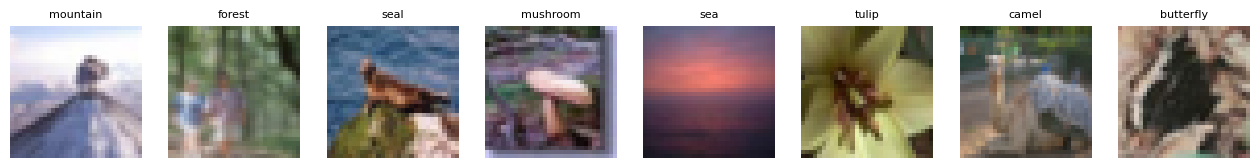

In [ ]:
# Pick the dataset class (CIFAR10 or CIFAR100) based on the DATASET setting
DS = {"CIFAR10": datasets.CIFAR10, "CIFAR100": datasets.CIFAR100}[DATASET]
# Download the training and test sets (no transform yet: these are raw PIL images, used for counting and previewing)
raw_train = DS("./data", train=True,  download=True)
raw_test  = DS("./data", train=False, download=True)
class_names = raw_train.classes            # list of class label names, e.g. "apple", "bus", ...
NUM_CLASSES = len(class_names)             # 10 for CIFAR10, 100 for CIFAR100
print(DATASET, "| classes:", NUM_CLASSES, "| train:", len(raw_train), "| test:", len(raw_test))

# Fixed index lists => every model sees EXACTLY the same training and test images, in the same order
rng = np.random.RandomState(SEED)                                            # seeded random generator (same shuffle every run)
train_idx = rng.permutation(len(raw_train))[:TRAIN_SUBSET or len(raw_train)].tolist()  # shuffle all indices, keep the first TRAIN_SUBSET
test_idx  = list(range(len(raw_test)))[:TEST_SUBSET or len(raw_test)]        # test images in fixed order (all of them if None)
print("Using", len(train_idx), "training images and", len(test_idx), "test images")

# Preview: show 8 test images with their true class names to confirm the data loaded correctly
fig, axs = plt.subplots(1, 8, figsize=(16, 2.4))                  # one row of 8 small plots
for ax, i in zip(axs, test_idx[:8]):                              # loop over the first 8 test images
    img, y = raw_test[i]; ax.imshow(img); ax.set_title(class_names[y], fontsize=8); ax.axis("off")  # draw image + label, hide axes
plt.show()   # 📸

In [ ]:
# Preprocessing: ImageNet normalization (what the pretrained weights expect).
# Images are upscaled from 32x32 to each network's native input size (224, or 299 for InceptionV3).
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # per-channel (R,G,B) mean/std of the ImageNet training data

def make_tf(size, train):
    """Build the image-preprocessing pipeline for a given input size."""
    t = [transforms.Resize(size)]                          # 1) enlarge the tiny 32x32 image to the size the CNN expects
    if train: t.append(transforms.RandomHorizontalFlip())  # 2) data augmentation, training only: randomly mirror the image
    t += [transforms.ToTensor(),                           # 3) convert the image to a tensor with values in 0..1
          transforms.Normalize(MEAN, STD)]                 # 4) normalize with ImageNet mean/std
    return transforms.Compose(t)                           # chain all steps into one transform

def make_loaders(size):
    """Return (train_loader, test_loader) with the correct preprocessing for this model's input size."""
    # Subset(...) keeps only the images at train_idx / test_idx => same images for every model
    tr = Subset(DS("./data", train=True,  transform=make_tf(size, True)),  train_idx)
    te = Subset(DS("./data", train=False, transform=make_tf(size, False)), test_idx)
    # shuffle=True for training (better learning); shuffle=False for testing (fixed order, reproducible)
    return (DataLoader(tr, BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True),
            DataLoader(te, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True))

## Task 2: Build and load the pretrained architectures
Each model is loaded with ImageNet weights and its final classification layer is replaced to output `NUM_CLASSES` scores.

In [ ]:
def build_model(name):
    """Load a pretrained CNN, replace its last layer for our dataset, and return (model, input_size)."""
    if name == "VGG16":
        m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)             # load VGG16 with ImageNet weights
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, NUM_CLASSES)     # swap the final layer: 1000 ImageNet classes -> NUM_CLASSES
        head = m.classifier[6]; size = 224                                        # remember the new layer (head) and the input size
    elif name == "ResNet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)       # load ResNet50 with ImageNet weights
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)                           # swap the final fully-connected layer
        head = m.fc; size = 224
    elif name == "InceptionV3":
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)  # load InceptionV3 with ImageNet weights
        m.aux_logits = False; m.AuxLogits = None           # drop auxiliary classifier (simplifies training)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)                           # swap the final layer
        head = m.fc; size = 299                                                   # InceptionV3 needs bigger 299x299 inputs
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)  # load the lightweight MobileNetV2
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)     # swap the final layer
        head = m.classifier[1]; size = 224
    else:
        raise ValueError(name)                                                    # unknown model name -> stop with an error
    if not FINE_TUNE_ALL:
        # Transfer learning: freeze every pretrained weight so it is not updated...
        for p in m.parameters(): p.requires_grad = False
        # ...then un-freeze only the new classifier layer so that is the only part that learns
        for p in head.parameters(): p.requires_grad = True
    return m.to(device), size                                                     # move the model to GPU/CPU and return it

MODEL_NAMES = ["VGG16", "ResNet50", "InceptionV3", "MobileNetV2"]   # the four architectures we will compare
# Optional extras for additional comparison: add "SqueezeNet", "WideResNet", "MNASNet" by extending build_model.

def count_params(m):  return sum(p.numel() for p in m.parameters())   # total number of weights in the model
def size_mb(m):       return sum(p.numel() * p.element_size() for p in m.parameters()) / 1024**2   # memory used by the weights, in MB (count x bytes each)

# Build each model once just to print its stats (input size, parameters, size, trainable parameters)
for n in MODEL_NAMES:
    m, s = build_model(n)
    print(f"{n:12s} input={s}  params={count_params(m)/1e6:7.2f}M  size={size_mb(m):7.1f} MB  trainable={sum(p.numel() for p in m.parameters() if p.requires_grad)/1e6:.2f}M")
    del m   # free memory before building the next model

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 122MB/s]


VGG16        input=224  params= 134.67M  size=  513.7 MB  trainable=0.41M
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 189MB/s]


ResNet50     input=224  params=  23.71M  size=   90.5 MB  trainable=0.20M
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 175MB/s] 


InceptionV3  input=299  params=  21.99M  size=   83.9 MB  trainable=0.20M
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 173MB/s]

MobileNetV2  input=224  params=   2.35M  size=    9.0 MB  trainable=0.13M


## Task 3: Train / fine-tune, save weights, reload, and classify

In [ ]:
def train_model(model, loader, epochs):
    """Fine-tune the model on the training loader for the given number of epochs."""
    params = [p for p in model.parameters() if p.requires_grad]    # only the weights that are allowed to learn
    opt = torch.optim.Adam(params, lr=LR)                          # Adam optimizer: updates those weights
    crit = nn.CrossEntropyLoss()                                   # loss function for multi-class classification
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))   # helper for mixed-precision (faster on GPU, avoids underflow)
    for ep in range(epochs):                                       # one epoch = one full pass over the training images
        # Frozen backbone => keep it in eval mode so BatchNorm/Dropout statistics stay as pretrained
        model.train() if FINE_TUNE_ALL else model.eval()
        tot, correct, loss_sum = 0, 0, 0.0                         # running totals for this epoch
        for x, y in loader:                                        # x = batch of images, y = their true labels
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)   # move the batch to the GPU
            opt.zero_grad(set_to_none=True)                        # clear gradients from the previous batch
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):   # mixed precision for speed
                out = model(x); loss = crit(out, y)                # forward pass -> class scores -> compute the loss
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()   # backward pass (gradients) + update the weights
            # accumulate statistics: total loss, number of correct predictions, number of images seen
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); tot += len(y)
        print(f"  epoch {ep+1}/{epochs}  loss={loss_sum/tot:.4f}  train acc={100*correct/tot:.2f}%")   # report average loss and accuracy

In [ ]:
# Fine-tune each model and save its weights to disk
train_time = {}                                            # store how long each model took to train
for n in MODEL_NAMES:
    print(f"\n=== Training {n} ===")
    model, size = build_model(n)                           # fresh pretrained model with the new classifier layer
    tr_loader, _ = make_loaders(size)                      # training loader at this model's input size (test loader not needed here)
    t0 = time.time(); train_model(model, tr_loader, EPOCHS); train_time[n] = time.time() - t0   # train and time it
    torch.save(model.state_dict(), f"{n}_{DATASET}.pth")   # save the trained weights to a .pth file
    print(f"  saved {n}_{DATASET}.pth  ({train_time[n]:.0f}s)")
    del model; torch.cuda.empty_cache()                    # free GPU memory before the next model


=== Training VGG16 ===


/tmp/ipykernel_372/2150662140.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))   # helper for mixed-precision (faster on GPU, avoids underflow)


  epoch 1/3  loss=2.1224  train acc=44.83%
  epoch 2/3  loss=1.1448  train acc=66.74%
  epoch 3/3  loss=0.8412  train acc=76.13%
  saved VGG16_CIFAR100.pth  (81s)

=== Training ResNet50 ===
  epoch 1/3  loss=2.8347  train acc=44.02%
  epoch 2/3  loss=1.4388  train acc=70.28%
  epoch 3/3  loss=1.0406  train acc=77.01%
  saved ResNet50_CIFAR100.pth  (58s)

=== Training InceptionV3 ===
  epoch 1/3  loss=2.7478  train acc=39.02%
  epoch 2/3  loss=1.5019  train acc=61.09%
  epoch 3/3  loss=1.2098  train acc=67.61%
  saved InceptionV3_CIFAR100.pth  (94s)

=== Training MobileNetV2 ===
  epoch 1/3  loss=2.6251  train acc=41.47%
  epoch 2/3  loss=1.3985  train acc=64.92%
  epoch 3/3  loss=1.1127  train acc=70.53%
  saved MobileNetV2_CIFAR100.pth  (54s)


In [ ]:
@torch.no_grad()                                           # no gradients needed when only predicting => faster, less memory
def get_scores(model, loader):
    """Return raw class scores (logits) for every test image + true labels."""
    model.eval()                                           # evaluation mode (no dropout, fixed BatchNorm)
    all_scores, all_labels = [], []
    for x, y in loader:                                    # go through the test set batch by batch
        all_scores.append(model(x.to(device)).float().cpu()); all_labels.append(y)   # predict, move results back to CPU, keep labels
    return torch.cat(all_scores), torch.cat(all_labels)    # join all batches into one big tensor each

@torch.no_grad()
def measure_inference_ms(model, loader, warmup=2, batches=10):
    """Average inference time per image in milliseconds (model forward pass only, GPU-synchronized)."""
    model.eval(); times, n_img = [], 0
    for i, (x, _) in enumerate(loader):
        x = x.to(device)
        if i < warmup: model(x); continue                  # first few batches are warm-up (GPU start-up is slow), not timed
        if device.type == "cuda": torch.cuda.synchronize() # wait for the GPU to finish earlier work before starting the timer
        t0 = time.perf_counter(); model(x)                 # time one forward pass
        if device.type == "cuda": torch.cuda.synchronize() # wait for the GPU to finish before stopping the timer
        times.append(time.perf_counter() - t0); n_img += len(x)   # record the time and how many images it covered
        if len(times) >= batches: break                    # stop after enough timed batches
    return 1000 * sum(times) / n_img                       # total seconds -> milliseconds, divided by images = ms per image

## Task 4: Rank-N accuracy

\[ \text{Rank-N} = \frac{\text{samples whose correct class is in the top-N predictions}}{\text{total test samples}} \times 100 \]

In [ ]:
def rank_n_accuracy(scores, labels, n):
    """scores: (num_samples, num_classes) tensor, labels: (num_samples,) tensor. Returns percent."""
    n = min(n, scores.shape[1])                              # N cannot be larger than the number of classes
    top_n = scores.topk(n, dim=1).indices                    # classes sorted high -> low, first N kept
    hit = (top_n == labels.unsqueeze(1)).any(dim=1)          # True if correct class is among them
    return 100.0 * hit.sum().item() / labels.numel()         # (number of hits / total images) x 100

def rank_n_accuracy_reference(scores, labels, n):
    """Slow, independent loop implementation used only to VERIFY the fast one."""
    correct = 0
    for s, y in zip(scores.numpy(), labels.numpy()):         # one image at a time: s = its scores, y = its true class
        order = np.argsort(-s)                               # sort highest -> lowest
        if y in order[:n]: correct += 1                      # count it if the true class is in the top N
    return 100.0 * correct / len(labels)

# --- Verification 1: the Fox example from the lab sheet (5 classes) ---
classes = ["Cat", "Dog", "Fox", "Wolf", "Deer"]
conf = torch.tensor([[0.42, 0.31, 0.18, 0.06, 0.03]])       # Cat, Dog, Fox, Wolf, Deer (model confidences)
y = torch.tensor([classes.index("Fox")])                    # the true answer is Fox (its rank here is 3rd)
for n in (1, 3, 5):
    print(f"Fox example  Rank-{n}:", "Correct" if rank_n_accuracy(conf, y, n) == 100 else "Incorrect")
# Expected: Rank-1 wrong (Cat is first), Rank-3 and Rank-5 correct (Fox is 3rd)
assert rank_n_accuracy(conf, y, 1) == 0 and rank_n_accuracy(conf, y, 3) == 100 and rank_n_accuracy(conf, y, 5) == 100

# --- Verification 2: fast vs. loop implementation on random scores ---
rs, rl = torch.randn(500, NUM_CLASSES), torch.randint(0, NUM_CLASSES, (500,))   # 500 fake score vectors + random labels
for n in (1, 5):
    assert abs(rank_n_accuracy(rs, rl, n) - rank_n_accuracy_reference(rs, rl, n)) < 1e-9   # both methods must agree
print("Verification passed ✔")   # 📸

Fox example  Rank-1: Incorrect
Fox example  Rank-3: Correct
Fox example  Rank-5: Correct
Verification passed ✔


## Task 5: Evaluate all models on the same test set and build the comparison table

In [ ]:
results, saved_scores = [], {}                             # results = rows of the table, saved_scores = each model's test scores
for n in MODEL_NAMES:
    model, size = build_model(n)                           # rebuild the same architecture
    model.load_state_dict(torch.load(f"{n}_{DATASET}.pth", map_location=device))   # load trained weights
    model.eval()                                           # evaluation mode
    _, te_loader = make_loaders(size)                      # test loader (same test images for every model)
    scores, labels = get_scores(model, te_loader)          # predict on all test images
    saved_scores[n] = scores                               # keep scores for the top-5 example later
    r1, r5 = rank_n_accuracy(scores, labels, 1), rank_n_accuracy(scores, labels, 5)   # Rank-1 and Rank-5 accuracy
    # cross-check with the loop version
    assert abs(r1 - rank_n_accuracy_reference(scores, labels, 1)) < 1e-9 and abs(r5 - rank_n_accuracy_reference(scores, labels, 5)) < 1e-9
    # add one row to the comparison table: accuracy, speed, parameters, and size
    results.append({"CNN Architecture": n, "Test images": len(labels),
                    "Rank-1 Accuracy (%)": round(r1, 2), "Rank-5 Accuracy (%)": round(r5, 2),
                    "Inference Time (ms/image)": round(measure_inference_ms(model, te_loader), 3),
                    "Parameters (M)": round(count_params(model)/1e6, 2), "Model Size (MB)": round(size_mb(model), 1)})
    print(f"{n}: done"); del model; torch.cuda.empty_cache()   # free GPU memory

df = pd.DataFrame(results)                                 # turn the list of rows into a table
df.to_csv(f"results_{DATASET}.csv", index=False)           # save the table as a CSV file
df   # 📸  (displays the table)

VGG16: done
ResNet50: done
InceptionV3: done
MobileNetV2: done


,CNN Architecture,Test images,Rank-1 Accuracy (%),Rank-5 Accuracy (%),Inference Time (ms/image),Parameters (M),Model Size (MB)
0,VGG16,10000,56.83,85.66,4.883,134.67,513.7
1,ResNet50,10000,65.55,90.96,2.776,23.71,90.5
2,InceptionV3,10000,58.01,85.28,3.724,21.99,83.9
3,MobileNetV2,10000,61.48,88.83,0.831,2.35,9.0


In [ ]:
# Sanity check: all models were evaluated on identical labels / same number of images
print("Test images per model:", df["Test images"].unique())   # should print ONE number (same for all models)
# Example of sorted predictions for one test image (top-5), per model
i = 0                                                          # look at the first test image
print("True class:", class_names[raw_test[test_idx[i]][1]])    # show its real label
for n in MODEL_NAMES:
    probs = saved_scores[n][i].softmax(0); top = probs.topk(5) # convert scores to probabilities, take the 5 highest
    print(f"{n:12s}", [(class_names[c], round(p, 3)) for p, c in zip(top.values.tolist(), top.indices.tolist())])   # (class name, probability) pairs

Test images per model: [10000]
True class: mountain
VGG16        [('mountain', 0.55), ('road', 0.445), ('train', 0.002), ('dolphin', 0.001), ('flatfish', 0.001)]
ResNet50     [('mountain', 0.221), ('skyscraper', 0.205), ('road', 0.15), ('train', 0.057), ('camel', 0.035)]
InceptionV3  [('road', 0.264), ('skyscraper', 0.154), ('mountain', 0.059), ('house', 0.039), ('train', 0.039)]
MobileNetV2  [('road', 0.689), ('mountain', 0.125), ('cloud', 0.072), ('skyscraper', 0.023), ('train', 0.015)]


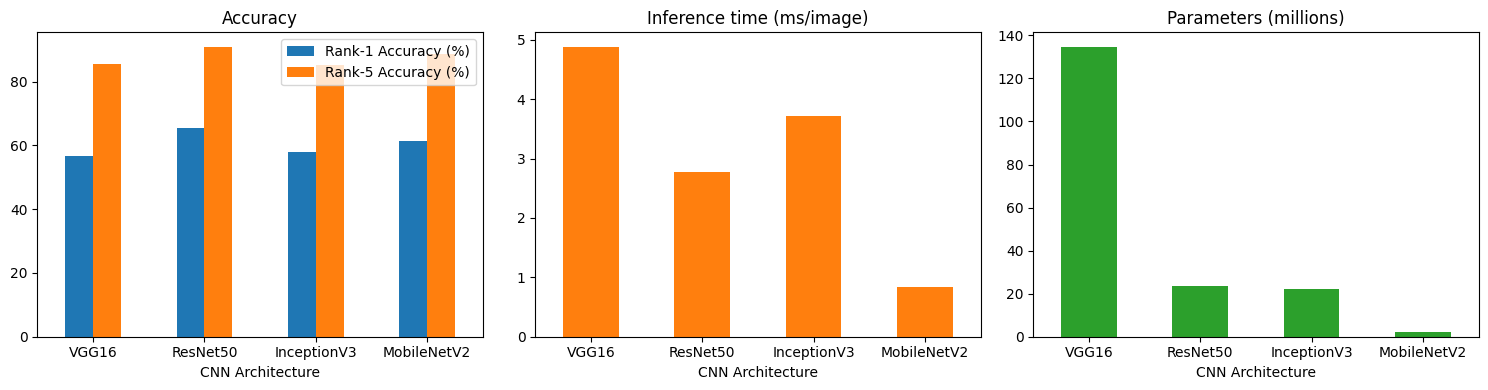

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))   # 3 charts side by side
# Chart 1: Rank-1 vs Rank-5 accuracy for each model
df.plot.bar(x="CNN Architecture", y=["Rank-1 Accuracy (%)", "Rank-5 Accuracy (%)"], ax=ax[0], rot=0, title="Accuracy")
# Chart 2: inference time per image (lower = faster)
df.plot.bar(x="CNN Architecture", y="Inference Time (ms/image)", ax=ax[1], rot=0, legend=False, color="tab:orange", title="Inference time (ms/image)")
# Chart 3: number of parameters in millions (model size/complexity)
df.plot.bar(x="CNN Architecture", y="Parameters (M)", ax=ax[2], rot=0, legend=False, color="tab:green", title="Parameters (millions)")
plt.tight_layout(); plt.show()   # tidy spacing, then display 📸

## Task 6: Analyze the results (computed automatically from your table)

In [ ]:
# Small helper: returns the model name with the max (mx=True) or min (mx=False) value in a column
best = lambda col, mx=True: df.loc[df[col].idxmax() if mx else df[col].idxmin(), "CNN Architecture"]
b1, b5 = best("Rank-1 Accuracy (%)"), best("Rank-5 Accuracy (%)")   # most accurate model at Rank-1 and at Rank-5
fast, big = best("Inference Time (ms/image)", False), best("Parameters (M)")   # fastest (lowest time) and biggest (most parameters)

# Balance score: accuracy per unit of compute (simple, transparent heuristic)
df["Rank-1 per ms"] = (df["Rank-1 Accuracy (%)"] / df["Inference Time (ms/image)"]).round(1)   # higher = more accuracy for each ms spent
balanced = df.loc[df["Rank-1 per ms"].idxmax(), "CNN Architecture"]   # model with the best accuracy/speed trade-off

# Print the automatic summary of the results
print("Highest Rank-1 accuracy      :", b1)
print("Highest Rank-5 accuracy      :", b5)
print("Fastest inference            :", fast)
print("Most parameters              :", big)
print("Same model best at Rank-1/5? :", "Yes" if b1 == b5 else f"No (Rank-1: {b1}, Rank-5: {b5})")
print("Best accuracy/efficiency     :", balanced, "(highest Rank-1 accuracy per ms of inference)")
df   # 📸  (displays the final table with the new column)

Highest Rank-1 accuracy      : ResNet50
Highest Rank-5 accuracy      : ResNet50
Fastest inference            : MobileNetV2
Most parameters              : VGG16
Same model best at Rank-1/5? : Yes
Best accuracy/efficiency     : MobileNetV2 (highest Rank-1 accuracy per ms of inference)


,CNN Architecture,Test images,Rank-1 Accuracy (%),Rank-5 Accuracy (%),Inference Time (ms/image),Parameters (M),Model Size (MB),Rank-1 per ms
0,VGG16,10000,56.83,85.66,4.883,134.67,513.7,11.6
1,ResNet50,10000,65.55,90.96,2.776,23.71,90.5,23.6
2,InceptionV3,10000,58.01,85.28,3.724,21.99,83.9,15.6
3,MobileNetV2,10000,61.48,88.83,0.831,2.35,9.0,74.0


### Written analysis _(edit after running; refer to your own numbers)_
1. **Highest Rank-1 / Rank-5:** …
2. **Fastest model and largest model:** …
3. **Did the Rank-1 winner also win Rank-5?** … (a model can lose at Rank-1 yet be close at Rank-5 because its correct answer is often 2nd–5th)
4. **Best balance of accuracy and efficiency:** … (justify using the table)
5. **Limitations:** only the new classification layer was trained (if `FINE_TUNE_ALL=False`), images were upscaled from 32×32, and timing depends on the Colab GPU assigned.

## D. Guide Questions

**1. What is the difference between Rank-1 and Rank-5 accuracy?**
Rank-1 counts a prediction as correct only when the single highest-scoring class is the true class. Rank-5 counts it as correct when the true class is anywhere among the five highest-scoring classes. Rank-5 ≥ Rank-1 always.

**2. Why is Rank-5 accuracy useful in image classification?**
Many classes look alike (e.g., different dog breeds, or maple vs. oak trees), and an image may contain several objects. Rank-5 shows whether the model "knows" the right answer even when it isn't its first choice. It is also useful in applications that show several suggestions (search, tagging, recommendation) or that pass candidates to a second-stage verifier. It was the standard ImageNet metric for this reason.

**3. Why should all architectures be evaluated using the same test dataset?**
So that differences in the scores come from the models and not from the data. Different test images could be easier or harder, giving an unfair comparison. Using identical images and labels (and a fixed order) also makes the results reproducible.

**4. How does the number of model parameters affect computational requirements?**
More parameters mean more memory for storing weights (and for activations/gradients during training), larger downloads and files, and generally more arithmetic per image, so slower inference and higher energy use. Parameter count is not the only factor (compute also depends on layer type and input size, e.g. VGG16's large fully connected layers vs. ResNet's convolutions), which is why you should also measure inference time.

**5. Why might a lightweight model perform differently from a deeper CNN?**
Lightweight models such as MobileNetV2 use depthwise-separable convolutions and fewer channels to cut computation, which reduces their representational capacity and can lower accuracy on hard or fine-grained tasks. In exchange they are much faster and smaller. Their features may also adapt differently when only the last layer is retrained, and on a simple dataset the accuracy gap may be small.

**6. Which architecture would you recommend for real-time image classification?**
_(Answer from your own table.)_ Choose the model with the lowest inference time that still meets an acceptable Rank-1/Rank-5 accuracy; the "Rank-1 per ms" column and the bar charts above support this. Mention the trade-off you accepted and that a mobile or embedded deployment would favour smaller models.

## E. Submission checklist
- [x] Working notebook (Runtime → Run all, no errors)
- [x] Pretrained VGG16, ResNet, InceptionV3, MobileNetV2 implemented
- [x] Classification results + Rank-1/Rank-5 implementation (with verification)
- [x] Comparison table (accuracy, inference time, parameters, size)
- [ ] Screenshots of 📸 outputs
- [ ] Fill in the written analysis and answer question 6 with your own results